# Exploration of the BRFSS data

Just looking, nothing is changed here. The cleaning itself is in `preprocessing.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from preprocessing import load_data, load_names, clean_codes

x_train, x_test, y_train, train_ids, test_ids = load_data()
names = np.array(load_names())
print(x_train.shape, x_test.shape, y_train.shape)

(328135, 321) (109379, 321) (328135,)


## Class balance

In [2]:
vals, counts = np.unique(y_train, return_counts=True)
print(dict(zip(vals, counts)))
print("positive rate", np.mean(y_train == 1))

{-1: 299160, 1: 28975}
positive rate 0.08830207079403295


About 8.8% positives. Predicting -1 for everyone already gives 91.2% accuracy and F1 = 0, so accuracy alone says very little here.

## Missing values

columns with missing fraction > 0.00: 239
columns with missing fraction > 0.05: 206
columns with missing fraction > 0.30: 177
columns with missing fraction > 0.50: 147
columns with missing fraction > 0.80: 116
columns with missing fraction > 0.95: 68
columns without any nan: 82
largest train/test difference: 0.004025228591234775


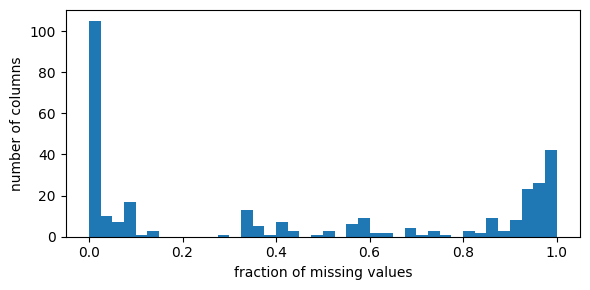

In [3]:
miss = np.isnan(x_train).mean(axis=0)
miss_test = np.isnan(x_test).mean(axis=0)
for t in [0, 0.05, 0.3, 0.5, 0.8, 0.95]:
    print("columns with missing fraction > %.2f: %d" % (t, (miss > t).sum()))
print("columns without any nan:", (miss == 0).sum())
print("largest train/test difference:", np.abs(miss - miss_test).max())

plt.figure(figsize=(6, 3))
plt.hist(miss, bins=40)
plt.xlabel("fraction of missing values")
plt.ylabel("number of columns")
plt.tight_layout()
plt.show()

Bimodal. Lots of columns are optional modules that only some states ask, or follow-up questions that get skipped, those are >90% nan. Same pattern in test.

## Categorical vs continuous

In [4]:
nuniq = np.array([len(np.unique(c[~np.isnan(c)])) for c in x_train.T])
for t in [1, 2, 3, 5, 10, 20, 50, 100]:
    print("columns with <= %3d unique values: %d" % (t, (nuniq <= t).sum()))
print("constant:", names[nuniq <= 1])
print("more than 100 values:", names[nuniq > 100])

columns with <=   1 unique values: 6
columns with <=   2 unique values: 20
columns with <=   3 unique values: 60
columns with <=   5 unique values: 159
columns with <=  10 unique values: 219
columns with <=  20 unique values: 241
columns with <=  50 unique values: 258
columns with <= 100 unique values: 276
constant: ['CTELENUM' 'COLGHOUS' 'STATERES' 'CTELNUM1' 'CELLFON2' 'CCLGHOUS']
more than 100 values: ['IDATE' 'SEQNO' '_PSU' 'WEIGHT2' 'HEIGHT3' 'FRUITJU1' 'FRUIT1' 'FVBEANS'
 'FVGREEN' 'FVORANG' 'VEGETAB1' 'EXEROFT1' 'EXERHMM1' 'EXERHMM2'
 'STRENGTH' 'HIVTSTD3' 'LONGWTCH' '_STSTR' '_STRWT' '_WT2RAKE' '_CLLCPWT'
 '_DUALCOR' '_LLCPWT' 'HTM4' 'WTKG3' '_BMI5' '_DRNKWEK' 'FRUTDA1_'
 'GRENDAY_' 'VEGEDA1_' '_FRUTSUM' '_VEGESUM' 'MAXVO2_' 'FC60_' 'PADUR1_'
 'PADUR2_' 'PAFREQ1_' '_MINAC11' '_MINAC21' 'PAMIN11_' 'PAMIN21_'
 'PA1MIN_' 'PAVIG11_' 'PAVIG21_' 'PA1VIGM_']


## Special codes

BRFSS codes "don't know" and "refused" as 7/9, 77/99, 777/999 depending on the width of the field, and often 8/88/888 for "none". Which columns contain them:

In [5]:
def has(code):
    return np.array([(c == code).any() for c in x_train.T])

mx = np.nanmax(x_train, axis=0)
for dk, ref in [(7, 9), (77, 99), (777, 999), (7777, 9999), (777777, 999999)]:
    cols = (mx == ref)
    print("max == %d: %d columns, %d of them also contain %d" % (ref, cols.sum(), (cols & has(dk)).sum(), dk))
print("contain 88:", names[has(88) & (mx == 99)])
print("contain 888:", names[has(888) & (mx == 999)])
print("contain 555:", names[has(555) & (mx == 999)])

max == 9: 167 columns, 121 of them also contain 7


max == 99: 48 columns, 38 of them also contain 77


max == 999: 18 columns, 16 of them also contain 777


max == 9999: 2 columns, 2 of them also contain 7777


max == 999999: 2 columns, 2 of them also contain 777777


contain 88: ['PHYSHLTH' 'MENTHLTH' 'POORHLTH' 'DIABAGE2' 'CHILDREN' 'DRNK3GE5'
 'EXRACT21' 'DOCTDIAB' 'CHKHEMO3' 'FEETCHK' 'ASRCHKUP' 'SCNTWRK1'
 'SCNTLWK1' 'ADPLEASR' 'ADDOWN' 'ADSLEEP' 'ADENERGY' 'ADEAT1' 'ADFAIL'
 'ADTHINK' 'ADMOVE' 'STRFREQ_']


contain 888: ['ALCDAY5' 'STRENGTH' 'BLDSUGAR' 'FEETCHK2' 'ASACTLIM']


contain 555: ['FRUITJU1' 'FRUIT1' 'FVBEANS' 'FVGREEN' 'FVORANG' 'VEGETAB1' 'FEETCHK2'
 'LONGWTCH']


In [6]:
# how much of the data are these codes, for the columns that use them
x_clean = clean_codes(x_train, names)
extra = np.isnan(x_clean).mean(axis=0) - miss
order = np.argsort(-extra)[:15]
for j in order:
    print("%-10s %.3f of the rows are dk/refused" % (names[j], extra[j]))

_CHISPNC   0.584 of the rows are dk/refused
_DUALUSE   0.375 of the rows are dk/refused
_HCVU651   0.359 of the rows are dk/refused
_INCOMG    0.179 of the rows are dk/refused
INCOME2    0.171 of the rows are dk/refused
_PASTAE1   0.130 of the rows are dk/refused
_PAREC1    0.130 of the rows are dk/refused
_PA30021   0.126 of the rows are dk/refused
_PA300R2   0.126 of the rows are dk/refused
_PACAT1    0.126 of the rows are dk/refused
_PA150R2   0.120 of the rows are dk/refused
_PAINDX1   0.120 of the rows are dk/refused
_VEGLT1    0.115 of the rows are dk/refused
_PASTRNG   0.099 of the rows are dk/refused
_FRTLT1    0.098 of the rows are dk/refused


Notes from the codebook:

- In `EMPLOY1` 7 means retired and 8 unable to work, so there only 9 is a missing code.
- Calculated variables (names starting with `_`) only use 9, e.g. in `_RACE` 7 and 8 are real groups.
- `_AGEG5YR` uses 14 and `_AGE65YR` uses 3 for missing, `_DRNKWEK` 99900, `DROCDY3_` 900, `MAXVO2_`/`FC60_` 999.
- 88 / 888 is "none" (e.g. `PHYSHLTH`: 88 = zero days), so it should become 0 and not nan.
- Columns like `ALCDAY5`, `FRUIT1`, `EXEROFT1` are coded as 1xx = per day/week, 2xx = per week/month. These are not numbers one can use directly. The calculated versions (`DROCDY3_`, `FRUTDA1_`, `PAFREQ1_`) are.
- `WEIGHT2` / `HEIGHT3` mix pounds/kg and feet+inches/cm, `WTKG3`, `HTM4`, `_BMI5` are the clean versions.

## A few features against the label

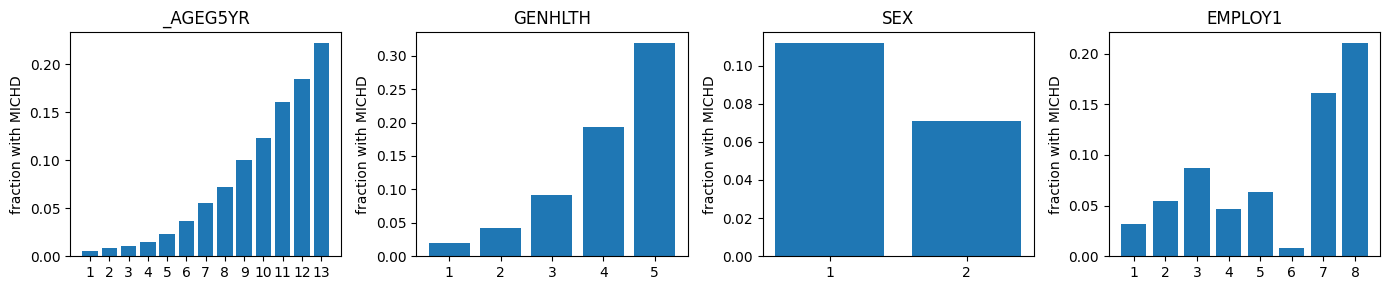

In [7]:
y = (y_train == 1)

def rate_plot(ax, name):
    c = x_clean[:, names == name][:, 0]
    vals = np.unique(c[~np.isnan(c)])
    ax.bar([str(int(v)) for v in vals], [y[c == v].mean() for v in vals])
    ax.set_title(name)
    ax.set_ylabel("fraction with MICHD")

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, name in zip(axes, ["_AGEG5YR", "GENHLTH", "SEX", "EMPLOY1"]):
    rate_plot(ax, name)
plt.tight_layout()
plt.show()

## Plan for preprocessing

dk/refused -> nan, none -> 0. Drop ids, dates, weights and the raw columns with a calculated version. Small categoricals one-hot with nan as its own category (for skipped follow-up questions "not asked" is information), the rest median + standardize. Start with dropping everything above 50% nan and see if that matters.